[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch06-short_workbook.ipynb)

# Three scores, three weights and one context vector

A decoder writing `black` scores the three French words `le`, `chat` and
`noir`. How much of its attention does each word get, and which vector does
the decoder read from them?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

WORDS = ["le", "chat", "noir"]
# The lecture's three encoder states, two numbers each.
STATES = np.array([[1.0, 0.0], [1.0, 1.0], [0.0, 2.0]])
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def scores_of(scores):  # three finite numbers, or one sentence saying what to type
    try:
        s = np.asarray(scores, dtype=float)
    except (TypeError, ValueError):
        s = np.array([])
    if s.shape != (3,) or not np.isfinite(s).all():
        raise Refused(f"SCORES is {scores!r}: SCORES takes three numbers in brackets, one each for le, chat and noir, such as [0, 1, 2].")
    return s


def softmax(scores):  # e to each score, divided by the sum: positive weights that add to 1
    s = scores_of(scores)
    e = np.exp(s - s.max())  # the largest score subtracted first: the same weights, and no overflow
    return e / e.sum()


def fmt(v):  # a vector as (0.335, 1.575)
    return "(" + ", ".join(f"{x:.3f}" for x in v) + ")"


def named(w):  # weights as le 0.090, chat 0.245, noir 0.665
    return ", ".join(f"{a} {b:.3f}" for a, b in zip(WORDS, w))


def weights_bars(scores):  # each word's score under it and its weight as a bar
    s, w = scores_of(scores), softmax(scores)
    print(f"weights: {named(w)} (sum {w.sum():.3f})")
    fig, ax = plt.subplots(figsize=(5, 2.6), layout="constrained")
    drawn = ax.bar([f"{a}\nscore {x:g}" for a, x in zip(WORDS, s)], w,
                   color=["C3" if x == w.max() else "0.6" for x in w])
    ax.bar_label(drawn, fmt="%.3f", fontsize=9)
    ax.set(ylim=(0, 1.1), ylabel="weight", title="softmax turns the scores into weights")
    plt.show()


def context_arrows(weights):  # the three states as grey arrows, the weighted sum as a red arrow
    c = np.asarray(weights) @ STATES
    print(f"weights: {named(weights)}; context vector: {fmt(c)}")
    fig, ax = plt.subplots(figsize=(4.2, 3.6), layout="constrained")
    for word, h in zip(WORDS, STATES):
        ax.annotate("", xy=h, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="0.55", lw=1.5))
        ax.text(h[0] + 0.05, h[1] + 0.05, f"{word} {fmt(h)}", fontsize=9, color="0.35")
    ax.annotate("", xy=c, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="C3", lw=2.4))
    ax.text(c[0] + 0.05, c[1] - 0.15, f"context {fmt(c)}", fontsize=9, color="C3")
    ax.set(xlim=(-0.2, 2.1), ylim=(-0.2, 2.3), aspect="equal", title="weights mix the states into one vector")
    plt.show()

## 1. Scores become weights

Softmax raises e to each score and divides by the sum, so every weight is
positive and the three add to 1. Run the cell for the scores of `black`: which
word gets the most weight, and is it 2 over the sum of the scores, two thirds?
Then set `SCORES` to `[0, 2, 2]`, and after that to `[0, 1, 3]`, and run it
again each time.

weights: le 0.090, chat 0.245, noir 0.665 (sum 1.000)


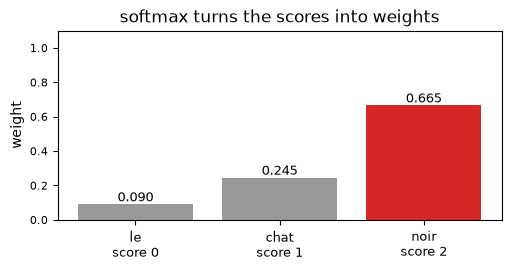

In [2]:
SCORES = [0, 1, 2]
weights_bars(SCORES)

### Solution

In [3]:
w012, w022, w013 = softmax([0, 1, 2]), softmax([0, 2, 2]), softmax([0, 1, 3])
display(Markdown(f"The scores of `black` give {w012[0]:.3f}, {w012[1]:.3f} and {w012[2]:.3f}: `noir` gets the most, "
                 f"{w012[2]:.3f}, near two thirds by coincidence. The scores 0, 1 and 3 give `noir` {w013[2]:.3f}, "
                 f"where 3 over the sum of the scores would be {3 / 4:.3f}. The scores 0, 2 and 2 give "
                 f"{w022[0]:.3f}, {w022[1]:.3f} and {w022[2]:.3f}. Each unit of score gap multiplies the ratio of "
                 f"two weights by e: `noir` over `chat` is {w012[2] / w012[1]:.3f} at a gap of 1 and "
                 f"{w013[2] / w013[1]:.3f} at a gap of 2."))

The scores of `black` give 0.090, 0.245 and 0.665: `noir` gets the most, 0.665, near two thirds by coincidence. The scores 0, 1 and 3 give `noir` 0.844, where 3 over the sum of the scores would be 0.750. The scores 0, 2 and 2 give 0.063, 0.468 and 0.468. Each unit of score gap multiplies the ratio of two weights by e: `noir` over `chat` is 2.718 at a gap of 1 and 7.389 at a gap of 2.

## 2. Weights mix the states into one vector

The decoder reads one vector: each encoder state scaled by its weight, the
three added. Run the cell: which state does the context vector of `black`
point closest to? Then set `SCORES` to `[0, 0, 0]`, which gives equal weights,
and run it again. Last, set `SCORES` to `[2, 3, 2]`, the scores of the decoder
step that writes `cat`: the dot products of its query (2, 1) with `le` (1, 0),
`chat` (1, 1) and `noir` (0, 2). Run it once more.

weights: le 0.090, chat 0.245, noir 0.665; context vector: (0.335, 1.575)


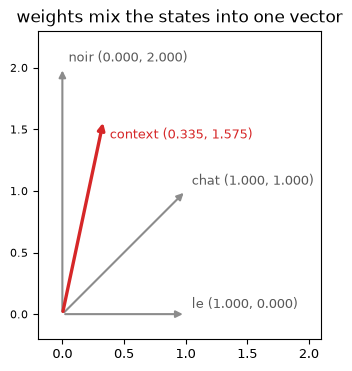

In [4]:
SCORES = [0, 1, 2]
context_arrows(softmax(SCORES))

### Solution

In [5]:
c_black, c_equal = softmax([0, 1, 2]) @ STATES, softmax([0, 0, 0]) @ STATES
s_cat = STATES @ np.array([2, 1])  # the query of the decoder step that writes cat
w_cat = softmax(s_cat)
display(Markdown(f"`black` reads {fmt(c_black)}, close to `noir` {fmt(STATES[2])}, which holds most of the weight. "
                 f"Equal weights give the mean of the three states, {fmt(c_equal)}, the same vector at every "
                 f"step. The decoder step that writes `cat` has the query (2, 1); its dot products with the three "
                 f"states are the scores {s_cat[0]:g}, {s_cat[1]:g} and {s_cat[2]:g}, which give the weights "
                 f"{w_cat[0]:.3f}, {w_cat[1]:.3f} and {w_cat[2]:.3f} and the context vector {fmt(w_cat @ STATES)}, "
                 f"closer to `chat`."))

`black` reads (0.335, 1.575), close to `noir` (0.000, 2.000), which holds most of the weight. Equal weights give the mean of the three states, (0.667, 1.000), the same vector at every step. The decoder step that writes `cat` has the query (2, 1); its dot products with the three states are the scores 2, 3 and 2, which give the weights 0.212, 0.576 and 0.212 and the context vector (0.788, 1.000), closer to `chat`.